<a href="https://colab.research.google.com/github/gabrielcabanilla1/EXSU-500-Clinical-NLP-large-language-models-rct/blob/main/notebooks/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
DATA_VERSION = 'PubMed_20k_RCT'
PROJECT_DIR = '/content/drive/MyDrive/exsu_project'
RAW_DIR = f'pubmed-rct/{DATA_VERSION}'
RESULTS_DIR = f'{PROJECT_DIR}/results/exploration'
CLASSES = ['BACKGROUND', 'OBJECTIVE', 'METHODS', 'RESULTS', 'CONCLUSIONS']
SPLITS = ['train', 'dev', 'test']
SEED = 42

In [2]:
import os
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
os.makedirs(RESULTS_DIR, exist_ok=True)
if not os.path.exists('pubmed-rct'):
    !git clone --depth 1 https://github.com/Franck-Dernoncourt/pubmed-rct.git
print('Raw data found:', os.path.exists(RAW_DIR))

Mounted at /content/drive
Cloning into 'pubmed-rct'...
remote: Enumerating objects: 19, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 19 (delta 5), reused 14 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (19/19), 177.08 MiB | 25.97 MiB/s, done.
Resolving deltas: 100% (5/5), done.
Updating files: 100% (13/13), done.
Raw data found: True


In [3]:
def read_split(path):
    rows, sentences, abstract_id = [], [], None

    def save_abstract():
        for i, (label, text) in enumerate(sentences):
            rows.append({'abstract_id': abstract_id, 'sentence_idx': i, 'n_sentences': len(sentences),
                         'label': label, 'text': text})

    for line in open(path, encoding='utf-8'):
        line = line.rstrip('\n')
        if line.startswith('###'):
            abstract_id, sentences = line[3:], []
        elif line.strip() == '':
            save_abstract()
            sentences = []
        else:
            label, text = line.split('\t', 1)
            sentences.append((label, text))
    save_abstract()
    df = pd.DataFrame(rows)
    df['position'] = df.sentence_idx / (df.n_sentences - 1).clip(lower=1)
    df['n_words'] = df.text.str.split().str.len()
    return df

data = {split: read_split(f'{RAW_DIR}/{split}.txt') for split in SPLITS}
sizes = pd.DataFrame({split: {'abstracts': df.abstract_id.nunique(), 'sentences': len(df),
                              'sentences per abstract (mean)': round(len(df) / df.abstract_id.nunique(), 2)}
                      for split, df in data.items()}).T
sizes.to_csv(f'{RESULTS_DIR}/split_sizes.csv')
display(sizes)

,abstracts,sentences,sentences per abstract (mean)
train,15000.0,180040.0,12.00
dev,2500.0,30212.0,12.08
test,2500.0,30135.0,12.05


In [4]:
import matplotlib.pyplot as plt
CLASS_COLORS = dict(zip(CLASSES, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']))
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e4e3df', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#3d3c38', 'xtick.color': '#5c5b56',
                     'ytick.color': '#5c5b56', 'legend.frameon': False})

sentences             percent            
                train   dev  test   train   dev  test
label                                                
BACKGROUND      21727  3449  3621    12.1  11.4  12.0
OBJECTIVE       13839  2376  2333     7.7   7.9   7.7
METHODS         59353  9964  9897    33.0  33.0  32.8
RESULTS         57953  9841  9713    32.2  32.6  32.2
CONCLUSIONS     27168  4582  4571    15.1  15.2  15.2

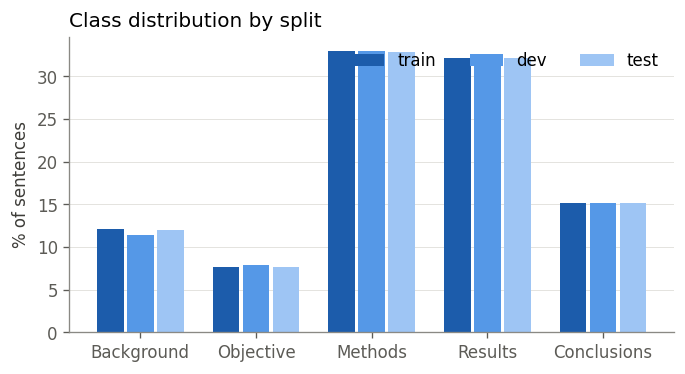

In [5]:
counts = pd.DataFrame({split: df.label.value_counts() for split, df in data.items()}).reindex(CLASSES)
shares = (counts / counts.sum() * 100).round(1)
class_table = pd.concat({'sentences': counts, 'percent': shares}, axis=1)
class_table.to_csv(f'{RESULTS_DIR}/class_distribution.csv')
display(class_table)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
width = 0.26
x = np.arange(len(CLASSES))
for i, (split, tone) in enumerate(zip(SPLITS, ['#1c5cab', '#5598e7', '#9ec5f4'])):
    ax.bar(x + (i - 1) * width, shares[split], width - 0.03, color=tone, label=split)
ax.set_xticks(x, [c.capitalize() for c in CLASSES])
ax.set_ylabel('% of sentences')
ax.set_title('Class distribution by split', loc='left')
ax.grid(axis='x', visible=False)
ax.legend(ncols=3, loc='upper right')
fig.savefig(f'{RESULTS_DIR}/fig_class_distribution.png')
plt.show()

label,BACKGROUND,OBJECTIVE,METHODS,RESULTS,CONCLUSIONS
relative position in abstract,,,,,
0-10%,49.1,40.9,9.8,0.1,0.1
10-20%,28.2,18.1,52.3,1.4,0.0
20-30%,11.0,7.0,77.9,4.0,0.0
30-40%,3.2,1.6,82.2,12.9,0.0
40-50%,1.1,0.4,67.8,30.6,0.1
50-60%,0.3,0.1,41.0,58.4,0.2
60-70%,0.1,0.1,17.8,80.4,1.6
70-80%,0.2,0.0,7.3,84.2,8.3
80-90%,0.7,0.0,2.6,59.9,36.7


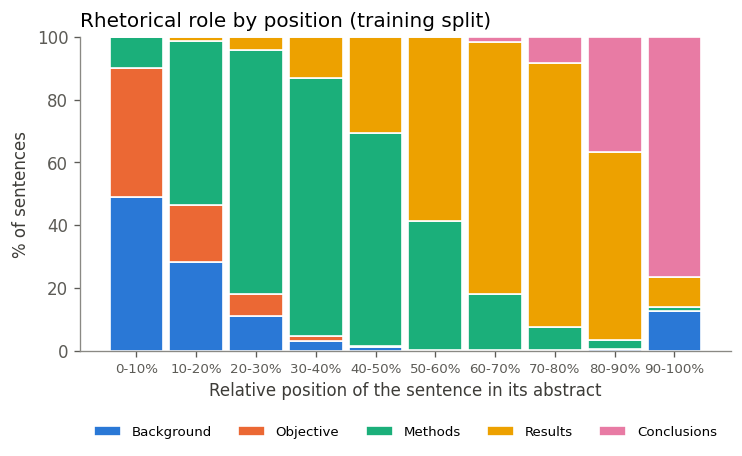

In [6]:
train = data['train']
N_POSITION_BINS = 10
train_bins = np.minimum((train.position * N_POSITION_BINS).astype(int), N_POSITION_BINS - 1)
by_position = (pd.crosstab(train_bins, train.label, normalize='index').reindex(columns=CLASSES) * 100).round(1)
by_position.index = [f'{b * 10}-{b * 10 + 10}%' for b in by_position.index]
by_position.index.name = 'relative position in abstract'
by_position.to_csv(f'{RESULTS_DIR}/class_by_position_train.csv')
display(by_position)

fig, ax = plt.subplots(figsize=(7, 3.4))
bottom = np.zeros(len(by_position))
for c in CLASSES:
    ax.bar(range(len(by_position)), by_position[c], 0.9, bottom=bottom, color=CLASS_COLORS[c],
           label=c.capitalize(), edgecolor='white', linewidth=1)
    bottom += by_position[c].to_numpy()
ax.set_xticks(range(len(by_position)), by_position.index, rotation=0, fontsize=8)
ax.set_xlabel('Relative position of the sentence in its abstract')
ax.set_ylabel('% of sentences')
ax.set_ylim(0, 100)
ax.grid(False)
ax.set_title('Rhetorical role by position (training split)', loc='left')
ax.legend(ncols=5, loc='upper center', bbox_to_anchor=(0.5, -0.2), fontsize=8)
fig.savefig(f'{RESULTS_DIR}/fig_class_by_position.png')
plt.show()

Sentences per abstract:


,count,mean,std,min,5%,50%,95%,max
train,15000.0,12.0,3.1,4.0,8.0,12.0,18.0,31.0
dev,2500.0,12.1,3.1,4.0,8.0,12.0,17.0,27.0
test,2500.0,12.1,3.1,4.0,8.0,12.0,18.0,28.0


Words per sentence (training split):


,count,mean,std,min,50%,95%,99%,max
label,,,,,,,,
BACKGROUND,21727.0,21.8,11.8,1.0,21.0,42.0,56.0,157.0
OBJECTIVE,13839.0,27.3,11.2,2.0,26.0,48.0,61.0,124.0
METHODS,59353.0,25.2,15.1,1.0,22.0,54.0,76.0,194.0
RESULTS,57953.0,30.5,18.6,1.0,26.0,65.0,94.0,296.0
CONCLUSIONS,27168.0,23.0,9.5,1.0,22.0,40.0,50.0,215.0


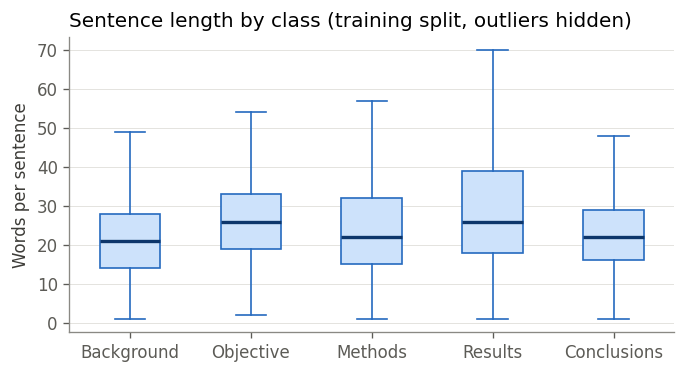

In [7]:
abstract_lengths = pd.DataFrame({split: df.groupby('abstract_id').size().describe(percentiles=[0.05, 0.5, 0.95])
                                 for split, df in data.items()}).T.round(1)
abstract_lengths.to_csv(f'{RESULTS_DIR}/sentences_per_abstract.csv')
print('Sentences per abstract:')
display(abstract_lengths)

words = train.groupby('label').n_words.describe(percentiles=[0.5, 0.95, 0.99]).reindex(CLASSES).round(1)
words.to_csv(f'{RESULTS_DIR}/words_per_sentence_train.csv')
print('Words per sentence (training split):')
display(words)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.boxplot([train.loc[train.label == c, 'n_words'] for c in CLASSES], showfliers=False, widths=0.5,
           patch_artist=True, boxprops={'facecolor': '#cde2fb', 'edgecolor': '#256abf'},
           medianprops={'color': '#0d366b', 'linewidth': 2}, whiskerprops={'color': '#256abf'},
           capprops={'color': '#256abf'})
ax.set_xticks(range(1, len(CLASSES) + 1), [c.capitalize() for c in CLASSES])
ax.set_ylabel('Words per sentence')
ax.set_title('Sentence length by class (training split, outliers hidden)', loc='left')
ax.grid(axis='x', visible=False)
fig.savefig(f'{RESULTS_DIR}/fig_sentence_length.png')
plt.show()

In [8]:
has = train.groupby('abstract_id').label.apply(lambda s: ('BACKGROUND' in set(s), 'OBJECTIVE' in set(s)))
convention = has.map({(True, True): 'both BACKGROUND and OBJECTIVE', (True, False): 'BACKGROUND only',
                      (False, True): 'OBJECTIVE only', (False, False): 'neither'}).value_counts()
convention = pd.DataFrame({'abstracts': convention, 'percent': (convention / convention.sum() * 100).round(1)})
convention.to_csv(f'{RESULTS_DIR}/background_objective_convention_train.csv')
print('How the opening of each training abstract is labelled:')
display(convention)

How the opening of each training abstract is labelled:


,abstracts,percent
label,,
OBJECTIVE only,6650,44.3
BACKGROUND only,5557,37.0
both BACKGROUND and OBJECTIVE,2773,18.5
neither,20,0.1


In [9]:
for c in CLASSES:
    example = train[train.label == c].sample(1, random_state=SEED).iloc[0]
    print(f"[{c}] sentence {example.sentence_idx + 1} of {example.n_sentences}\n{example.text}\n")

[BACKGROUND] sentence 1 of 11
A live oral cholera vaccine VA 1.4 developed from a non-toxigenic Vibrio cholerae O1 El Tor strain using ctxB gene insertion was further developed into a clinical product following cGMP and was evaluated in a double-blind randomized placebo controlled parallel group two arm trial with allocation ratio of 11 for safety and immunogenicity in men and women aged 18-60 years from Kolkata , India .

[OBJECTIVE] sentence 1 of 11
The purpose of this study was to characterize the relationship between heart rate and post-discharge outcomes in patients with hospitalization for heart failure ( HHF ) with reduced ejection fraction ( EF ) in sinus rhythm .

[METHODS] sentence 9 of 24
We assessed safety in all patients who received at least one dose of alectinib .

[RESULTS] sentence 8 of 10
Early complication rate was 5.1 % in USG group , 2.8 % in the IJB , and 0 % in the SCB ( P = 0.401 ) .

[CONCLUSIONS] sentence 13 of 13
Change of unhelpful behavioral patterns and in